Part A — Manual EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = {
    'show_id': ['S1', 'S2', 'S3', 'S4', 'S5',
                'S6', 'S7', 'S8', 'S9', 'S10'],
    'type': ['Movie', 'TV Show', 'Movie', 'Movie', 'TV Show',
             'Movie', 'TV Show', 'Movie', 'Movie', 'TV Show'],
    'title': ['Movie A', 'Show B', 'Movie C', 'Movie D', 'Show E',
              'Movie F', 'Show G', 'Movie H', 'Movie I', 'Show J'],
    'director': ['Director A', None, 'Director C', 'Director D',
                 None, 'Director F', 'Director G', None,
                 'Director I', 'Director J'],
    'country': ['India', 'USA', 'India', None, 'UK',
                'USA', 'India', 'UK', None, 'India'],
    'rating': ['TV-MA', 'TV-14', 'PG-13', 'TV-MA', 'TV-14',
               'PG', 'TV-MA', 'PG-13', 'TV-14', 'TV-MA'],
    'duration': ['120 min', '2 Seasons', '150 min', '130 min',
                 '3 Seasons', '180 min', '1 Season', '140 min',
                 '200 min', '4 Seasons']
}

df = pd.DataFrame(data)

print("Netflix Dataset:")
print(df)

Netflix Dataset:
  show_id     type    title    director country rating   duration
0      S1    Movie  Movie A  Director A   India  TV-MA    120 min
1      S2  TV Show   Show B        None     USA  TV-14  2 Seasons
2      S3    Movie  Movie C  Director C   India  PG-13    150 min
3      S4    Movie  Movie D  Director D    None  TV-MA    130 min
4      S5  TV Show   Show E        None      UK  TV-14  3 Seasons
5      S6    Movie  Movie F  Director F     USA     PG    180 min
6      S7  TV Show   Show G  Director G   India  TV-MA   1 Season
7      S8    Movie  Movie H        None      UK  PG-13    140 min
8      S9    Movie  Movie I  Director I    None  TV-14    200 min
9     S10  TV Show   Show J  Director J   India  TV-MA  4 Seasons


In [3]:
print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)

First 5 rows:
  show_id     type    title    director country rating   duration
0      S1    Movie  Movie A  Director A   India  TV-MA    120 min
1      S2  TV Show   Show B        None     USA  TV-14  2 Seasons
2      S3    Movie  Movie C  Director C   India  PG-13    150 min
3      S4    Movie  Movie D  Director D    None  TV-MA    130 min
4      S5  TV Show   Show E        None      UK  TV-14  3 Seasons

Dataset Shape:
(10, 7)

Column Names:
Index(['show_id', 'type', 'title', 'director', 'country', 'rating',
       'duration'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   show_id   10 non-null     object
 1   type      10 non-null     object
 2   title     10 non-null     object
 3   director  7 non-null      object
 4   country   8 non-null      object
 5   rating    10 non-null     object
 6   duration 

In [4]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
show_id     0
type        0
title       0
director    3
country     2
rating      0
duration    0
dtype: int64

Total Missing Values:
5


In [5]:
df['director'] = df['director'].fillna('Unknown')

df['country'] = df['country'].fillna(
    df['country'].mode()[0]
)

print("Missing Values After Handling:")
print(df.isnull().sum())

Missing Values After Handling:
show_id     0
type        0
title       0
director    0
country     0
rating      0
duration    0
dtype: int64


In [6]:
df['duration_int'] = pd.to_numeric(
    df['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

print(df[['title', 'type', 'duration', 'duration_int']])

     title     type   duration  duration_int
0  Movie A    Movie    120 min           120
1   Show B  TV Show  2 Seasons             2
2  Movie C    Movie    150 min           150
3  Movie D    Movie    130 min           130
4   Show E  TV Show  3 Seasons             3
5  Movie F    Movie    180 min           180
6   Show G  TV Show   1 Season             1
7  Movie H    Movie    140 min           140
8  Movie I    Movie    200 min           200
9   Show J  TV Show  4 Seasons             4


In [7]:
movie_duration = df.loc[
    df['type'] == 'Movie', 'duration_int'
].dropna()

Q1 = movie_duration.quantile(0.25)
Q3 = movie_duration.quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = movie_duration[
    (movie_duration < lower_limit) |
    (movie_duration > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Outliers:")
print(outliers)

Q1: 132.5
Q3: 172.5
IQR: 40.0
Lower Limit: 72.5
Upper Limit: 232.5
Outliers:
Series([], Name: duration_int, dtype: int64)


In [8]:
df_clean = df.copy()

valid_movies = df_clean['type'] == 'Movie'

movie_values = df_clean.loc[valid_movies, 'duration_int']

df_clean = df_clean.loc[
    ~valid_movies |
    (
        movie_values.ge(lower_limit) &
        movie_values.le(upper_limit)
    )
].copy()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

Original Dataset Shape: (10, 8)
Cleaned Dataset Shape: (10, 8)


In [9]:
print("Descriptive Statistics:")
print(df_clean.describe(include='all'))

print("\nMean Movie Duration:")
print(df_clean.loc[
    df_clean['type'] == 'Movie', 'duration_int'
].mean())

print("\nMedian Movie Duration:")
print(df_clean.loc[
    df_clean['type'] == 'Movie', 'duration_int'
].median())

print("\nMode of Ratings:")
print(df_clean['rating'].mode())

print("\nContent Type Counts:")
print(df_clean['type'].value_counts())

print("\nRating Counts:")
print(df_clean['rating'].value_counts())

Descriptive Statistics:
       show_id   type    title director country rating duration  duration_int
count       10     10       10       10      10     10       10     10.000000
unique      10      2       10        8       3      4       10           NaN
top         S1  Movie  Movie A  Unknown   India  TV-MA  120 min           NaN
freq         1      6        1        3       6      4        1           NaN
mean       NaN    NaN      NaN      NaN     NaN    NaN      NaN     93.000000
std        NaN    NaN      NaN      NaN     NaN    NaN      NaN     81.199343
min        NaN    NaN      NaN      NaN     NaN    NaN      NaN      1.000000
25%        NaN    NaN      NaN      NaN     NaN    NaN      NaN      3.250000
50%        NaN    NaN      NaN      NaN     NaN    NaN      NaN    125.000000
75%        NaN    NaN      NaN      NaN     NaN    NaN      NaN    147.500000
max        NaN    NaN      NaN      NaN     NaN    NaN      NaN    200.000000

Mean Movie Duration:
153.33333333333334

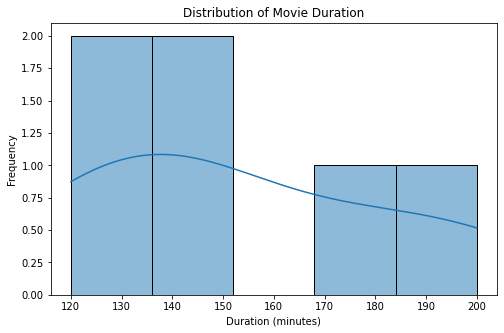

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean[df_clean['type'] == 'Movie'],
    x='duration_int',
    bins=5,
    kde=True
)

plt.title('Distribution of Movie Duration')
plt.xlabel('Duration (minutes)')
plt.ylabel('Frequency')

plt.show()

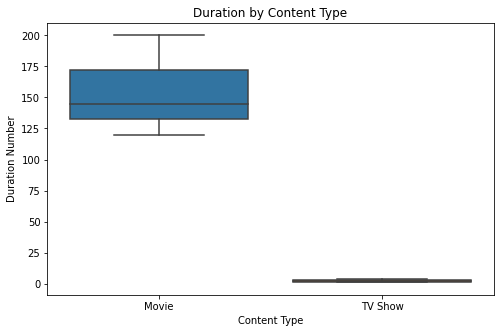

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x='type',
    y='duration_int',
    data=df_clean
)

plt.title('Duration by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Duration Number')

plt.show()

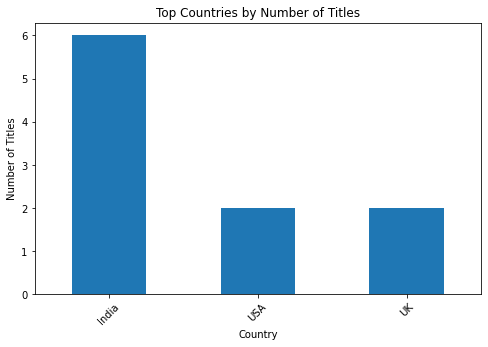

In [12]:
plt.figure(figsize=(8, 5))

df_clean['country'].value_counts().head(10).plot(
    kind='bar'
)

plt.title('Top Countries by Number of Titles')
plt.xlabel('Country')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.show()

In [13]:
print("Most Common Rating:")
print(df_clean['rating'].mode()[0])

print("\nMost Common Content Type:")
print(df_clean['type'].mode()[0])

print("\nCountry with Most Titles:")
print(df_clean['country'].value_counts().idxmax())

print("\nTotal Movies:")
print((df_clean['type'] == 'Movie').sum())

print("\nTotal TV Shows:")
print((df_clean['type'] == 'TV Show').sum())

Most Common Rating:
TV-MA

Most Common Content Type:
Movie

Country with Most Titles:
India

Total Movies:
6

Total TV Shows:
4


Part B — Automated EDA using ydata-profiling

In [14]:
%pip install ydata-profiling

In [15]:
loan_data = {
    'Income': [25000, 40000, 55000, 30000, 80000,
               65000, 45000, 90000, 35000, 70000],
    'Credit_Score': [580, 650, 720, 600, 780,
                     750, 680, 800, 620, 760],
    'Loan_Amount': [100000, 150000, 200000, 120000, 300000,
                    250000, 180000, 350000, 130000, 280000],
    'Existing_Debt': [20000, 30000, 25000, 40000, 15000,
                      18000, 35000, 10000, 45000, 20000],
    'Default': ['Yes', 'No', 'No', 'Yes', 'No',
                'No', 'Yes', 'No', 'Yes', 'No']
}

loan_df = pd.DataFrame(loan_data)

print(loan_df)

   Income  Credit_Score  Loan_Amount  Existing_Debt Default
0   25000           580       100000          20000     Yes
1   40000           650       150000          30000      No
2   55000           720       200000          25000      No
3   30000           600       120000          40000     Yes
4   80000           780       300000          15000      No
5   65000           750       250000          18000      No
6   45000           680       180000          35000     Yes
7   90000           800       350000          10000      No
8   35000           620       130000          45000     Yes
9   70000           760       280000          20000      No


In [16]:
from ydata_profiling import ProfileReport

profile = ProfileReport(
    loan_df,
    title='Credit Risk Analysis - EDA Report',
    explorative=True
)

profile.to_file('eda_report.html')

print("EDA report generated successfully!")

C:\Users\samar\AppData\Roaming\Python\Python38\site-packages\numba\core\decorators.py:262: NumbaDeprecationWarning: numba.generated_jit is deprecated. Please see the documentation at: https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-generated-jit for more information and advice on a suitable replacement.
  warnings.warn(msg, NumbaDeprecationWarning)
c:\Users\samar\anaconda3\lib\site-packages\visions\backends\shared\nan_handling.py:51: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def hasna(x: np.ndarray) -> bool:


Export report to file: 100%|██████████| 1/1 [00:00<00:00, 124.92it/s]

EDA report generated successfully!


In [17]:
from IPython.display import IFrame, display

display(IFrame(
    src='eda_report.html',
    width='100%',
    height=600
))

In [19]:
import os
print(os.path.abspath("eda_report.html"))

d:\IT\FDSL\eda_report.html


In [20]:
import os
import webbrowser

report_path = os.path.abspath("eda_report.html")
webbrowser.open("file:///" + report_path.replace("\\", "/"))

True